# **Tutorial:** Custom YOLO Object Detection with RoboFlow

In this tutorial, you'll learn how to create a custom YOLO object detection model using your own classes and annotations with RoboFlow.

### **Step 1: Install Required Dependencies**

In [1]:
%pip install --upgrade ultralytics
%pip install opencv-python
%pip install roboflow
%pip install matplotlib
%pip install numpy==1.26.4 --force-reinstall

  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.5 MB ? eta -:--:--
   ---------------------------- ----------- 1.0/1.5 MB 2.7 MB/s eta 0:00:01
   ---------------------------------------- 1.5/1.5 MB 2.9 MB/s eta 0:00:00
   ---------------------------------------- 0.0/911.5 kB ? eta -:--:--
   ---------------------------------- ----- 786.4/911.5 kB 4.4 MB/s eta 0:00:01
   ---------------------------------------- 911.5/911.5 kB 3.9 MB/s eta 0:00:00
   ---------------------------------------- 0.0/53.9 MB ? eta -:--:--
    --------------------------------------- 0.8/53.9 MB 4.7 MB/s eta 0:00:12
   - -------------------------------------- 1.8/53.9 MB 4.8 MB/s eta 0:00:11
   - -------------------------------------- 2.6/53.9 MB 4.6


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/43.8 MB ? eta -:--:--
    --------------------------------------- 0.8/43.8 MB 4.1 MB/s eta 0:00:11
   - -------------------------------------- 1.8/43.8 MB 4.8 MB/s eta 0:00:09
   -- ------------------------------------- 2.6/43.8 MB 4.5 MB/s eta 0:00:10
   --- ------------------------------------ 3.7/43.8 MB 4.6 MB/s eta 0:00:09
   ---- ----------------------------------- 4.7/43.8 MB 4.7 MB/s eta 0:00:09
   ----- ---------------------------------- 6.0/43.8 MB 4.6 MB/s eta 0:00:09
   ------ --------------------------------- 7.1/43.8 MB 4.8 MB/s eta 0:00:08
   ------- -------------------------------- 8.1/43.8 MB 4.8 MB/s eta 0:00:08
   -------- ------------------------------- 8.9/43.8 MB 4.7 MB/s eta 0:00:08
   --------- ------------------------------ 10.0/43.8 MB 4.6 MB/s eta 0:00:08
   --------- ------------------------------ 10.7/43.8 MB 4.5 MB/s eta 0:00:08
   ---------- ----------------------------- 11.5/43.8 MB 4.5 MB/s eta 0:00:08
   


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


     ---------------------------------------- 0.0/15.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/15.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/15.8 MB ? eta -:--:--
     - -------------------------------------- 0.5/15.8 MB 1.9 MB/s eta 0:00:09
     -- ------------------------------------- 1.0/15.8 MB 2.8 MB/s eta 0:00:06
     ---- ----------------------------------- 1.8/15.8 MB 2.6 MB/s eta 0:00:06
     ------ --------------------------------- 2.6/15.8 MB 3.0 MB/s eta 0:00:05
     -------- ------------------------------- 3.4/15.8 MB 3.3 MB/s eta 0:00:04
     ---------- ----------------------------- 4.2/15.8 MB 3.4 MB/s eta 0:00:04
     ------------- -------------------------- 5.2/15.8 MB 3.5 MB/s eta 0:00:04
     --------------- ------------------------ 6.3/15.8 MB 3.7 MB/s eta 0:00:03
     ----------------- ---------------------- 7.1/15.8 MB 3.7 MB/s eta 0:00:03
     -------------------- ------------------- 8.1/15.8 MB 3.8 MB/s eta 0:

  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [21 lines of output]
      + c:\Users\eduar\Downloads\MD IA\.venv\Scripts\python.exe C:\Users\eduar\AppData\Local\Temp\pip-install-d0wbcck6\numpy_91e5fc9c80004fc1b607a0a79c7c601c\vendored-meson\meson\meson.py setup C:\Users\eduar\AppData\Local\Temp\pip-install-d0wbcck6\numpy_91e5fc9c80004fc1b607a0a79c7c601c C:\Users\eduar\AppData\Local\Temp\pip-install-d0wbcck6\numpy_91e5fc9c80004fc1b607a0a79c7c601c\.mesonpy-r2uh_6qr -Dbuildtype=release -Db_ndebug=if-release -Db_vscrt=md --native-file=C:\Users\eduar\AppData\Local\Temp\pip-install-d0wbcck6\numpy_91e5fc9c80004fc1b607a0a79c7c601c\.mesonpy-r2uh_6qr\meson-python-native-file.ini
      The Meson build system
      Version: 1.2.99
      Source dir: C:\Users\eduar\AppData\Local\Temp\pip-install-d0wbcck6\numpy_91e5fc9c80004fc1b607a0a79c7c601c
      Build dir: C:\Users\eduar\AppData\Local\Temp\pip-install-d0wbcck6\nump

In [2]:
import sys

print("Versión de Python:", sys.version)
print("Ruta de Python:", sys.executable)

Versión de Python: 3.13.3 (tags/v3.13.3:6280bb5, Apr  8 2025, 14:47:33) [MSC v.1943 64 bit (AMD64)]
Ruta de Python: c:\Users\eduar\Downloads\MD IA\.venv\Scripts\python.exe


In [1]:
import sys

print(sys.version)
print(sys.executable)

3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
c:\Users\eduar\Downloads\MD IA\.venv_yolo10\Scripts\python.exe


### **Step 2: Import Required Libraries**

In [2]:
import cv2
from roboflow import Roboflow
from ultralytics import YOLO
import matplotlib.pyplot as plt
import numpy as np
import os
from IPython.display import Image, display

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\eduar\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


### **Step 3: Set Up RoboFlow Account**

1. Go to RoboFlow and create a free account
2. Create a new project and select "Object Detection" as project type
3. Choose "YOLOv26" as the model format

### **Step 4: Upload and Annotate Your Images**

#### Using RoboFlow Web Interface:

1. Click "Upload" to add your images
2. Use the annotation tool to draw bounding boxes around objects
3. Assign the correct class labels to each bounding box
4. Apply preprocessing and augmentation as needed

### **Step 5. Download your Custom your Dataset**

1. In RoboFlow, go to your project dashboard
2. Click "Generate" to create a dataset version
3. Apply any desired augmentations
4. Click "Export" and select "YOLOv**x**" format (**x** the version you are using)
5. Copy the download code

In [3]:
from roboflow import Roboflow
from getpass import getpass

# Ingresar la clave privada
api_key = getpass("Ingresa tu API Key: ").strip()

# Conectar con Roboflow
rf = Roboflow(api_key=api_key)

# Acceder al workspace
workspace = rf.workspace("wilsons-workspace-1kq0t")

print("Workspace conectado correctamente")

# Acceder a nuestro proyecto
project = workspace.project("detector-objetos-personalizados")

print("Proyecto conectado correctamente")

# Seleccionar la versión
version = project.version(1)

# Descargar el dataset
dataset = version.download("yolo26")

print("Dataset descargado en:", dataset.location)

loading Roboflow workspace...
Workspace conectado correctamente
loading Roboflow project...
Proyecto conectado correctamente



Extracting Dataset Version Zip to Detector-objetos-personalizados-1 in yolo26:: 100%|██████████| 216/216 [00:00<00:00, 665.11it/s]

Dataset descargado en: c:\Users\eduar\Downloads\MD IA\Actividad 10\Detector-objetos-personalizados-1


### **Step 6: Train Your Custom YOLO Model**

In [5]:
from ultralytics import YOLO

# Cargar el modelo preentrenado YOLO26
model = YOLO("yolo26n.pt")

# Entrenar nuestro modelo personalizado
results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=20,
    imgsz=640,
    batch=8,
    name="custom_yolo_model",
    workers=0
)

Ultralytics 8.4.212  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core i5-1035G1 1.00GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\eduar\Downloads\MD IA\Actividad 10\Detector-objetos-personalizados-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name

### **Step 7: Evaluate Your Model**

In [6]:
from ultralytics import YOLO
from pathlib import Path

# Ubicación del mejor modelo entrenado
model_path = Path(
    r"C:\Users\eduar\Downloads\MD IA\runs\detect\custom_yolo_model\weights\best.pt"
)

# Cargar el modelo entrenado
custom_model = YOLO(str(model_path))

# Evaluar el modelo
metrics = custom_model.val(
    data=f"{dataset.location}/data.yaml",
    split="val",
    workers=0
)

# Mostrar las métricas
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall: {metrics.box.mr:.4f}")
print(f"mAP50: {metrics.box.map50:.4f}")
print(f"mAP50-95: {metrics.box.map:.4f}")

Ultralytics 8.4.212  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core i5-1035G1 1.00GHz)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.5±0.1 ms, read: 58.4±15.6 MB/s, size: 60.2 KB)
val: Scanning C:\Users\eduar\Downloads\MD IA\Actividad 10\Detector-objetos-personalizados-1\valid\labels.cache... 9 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 9/9  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.1s/it 2.1s
                   all          9         11      0.988          1      0.995      0.866
                 libro          4          4      0.992          1      0.995      0.849
                 mouse          7          7      0.984          1      0.995      0.884
Speed: 4.4ms preprocess, 158.3ms inference, 0.0ms loss, 8.9ms postprocess per image
Results saved to C:\Users\eduar\Downloads\MD IA\runs\detect\val
Precision: 0.9881
Recall: 1.0000

### Análisis de los resultados

El modelo YOLO26n entrenado para la detección de libros y mouse obtuvo una precisión de 98,81 %, un Recall de 100 %, un mAP50 de 99,50 % y un mAP50-95 de 86,64 %.

Estos resultados indican que el modelo presenta un buen desempeño en la identificación y localización de ambas clases dentro del conjunto de validación. En particular, la clase mouse obtuvo un mAP50-95 de 88,4 %, mientras que la clase libro alcanzó un 84,9 %.

Sin embargo, debido al tamaño reducido del conjunto de datos, es necesario realizar pruebas adicionales con imágenes no utilizadas durante el entrenamiento y con detección en tiempo real mediante la webcam, para comprobar su capacidad de generalización.

### **Step 8: Test Your Custom Model on an Image**


image 1/1 C:\Users\eduar\Downloads\MD IA\Actividad 10\prueba7.jpeg: 640x480 1 libro, 1 mouse, 68.5ms
Speed: 3.1ms preprocess, 68.5ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 480)


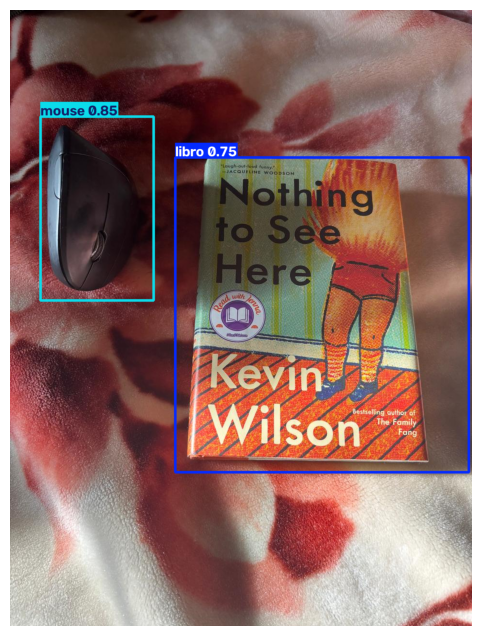

In [6]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Cargar nuestro modelo entrenado
custom_model = YOLO(
    r"C:\Users\eduar\Downloads\MD IA\runs\detect\custom_yolo_model\weights\best.pt"
)

# Probar el modelo con una imagen nueva
results = custom_model(
    r"C:\Users\eduar\Downloads\MD IA\Actividad 10\prueba7.jpeg",
    conf=0.25
)

# Mostrar los resultados
%matplotlib inline

for result in results:
    img = result.plot()
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 8))
    plt.imshow(img_rgb)
    plt.axis("off")
    plt.show()

### Análisis de la predicción en una imagen nueva

El modelo YOLO26n logró detectar correctamente un libro y un mouse en una fotografía que no formó parte del conjunto de entrenamiento.

La detección del libro presentó una confianza de 75 %, mientras que la detección del mouse alcanzó una confianza de 85 %.

Se observa que el rectángulo delimitador del mouse se ajusta adecuadamente a su ubicación, mientras que el correspondiente al libro incluye parte del fondo. Esto evidencia que, aunque el modelo identifica correctamente ambas clases, todavía existen oportunidades de mejora en la precisión espacial de las detecciones.

Los resultados permiten comprobar la capacidad del modelo para reconocer los objetos en imágenes nuevas, aunque se requieren pruebas adicionales para evaluar su generalización.

### **Step 9: Test Your Custom Model on Video**

Cámara iniciada correctamente
Detección en tiempo real durante 60 segundos


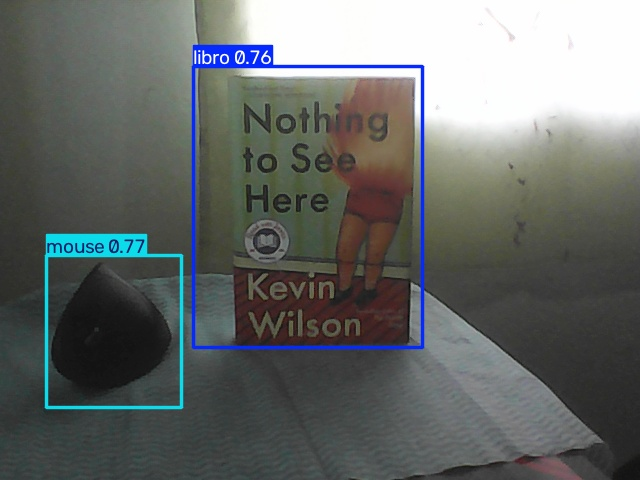

Cámara finalizada correctamente


In [8]:
from ultralytics import YOLO
import cv2
from IPython.display import display, Image
import time

# Cargar el modelo entrenado
custom_model = YOLO(
    r"C:\Users\eduar\Downloads\MD IA\runs\detect\custom_yolo_model\weights\best.pt"
)

# Abrir la cámara web
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("No se pudo abrir la cámara")

else:
    print("Cámara iniciada correctamente")
    print("Detección en tiempo real durante 60 segundos")

    inicio = time.time()
    visualizacion = None

    try:
        while time.time() - inicio < 20:

            # Capturar imagen de la cámara
            ret, frame = cap.read()

            if not ret:
                break

            # Detectar libro y mouse
            results = custom_model(
                frame,
                conf=0.25,
                verbose=False
            )

            # Dibujar los rectángulos
            annotated_frame = results[0].plot()

            # Convertir la imagen a JPEG
            success, buffer = cv2.imencode(
                ".jpg", annotated_frame
            )

            if not success:
                continue

            imagen = Image(data=buffer.tobytes())

            # Mostrar el video dentro del notebook
            if visualizacion is None:
                visualizacion = display(
                    imagen,
                    display_id=True
                )
            else:
                visualizacion.update(imagen)

    finally:
        cap.release()
        print("Cámara finalizada correctamente")

### Análisis de la detección en tiempo real

Se implementó un sistema de detección de objetos en tiempo real utilizando el modelo YOLO26n entrenado y la cámara web de la computadora. La captura de imágenes se realizó mediante OpenCV y los resultados se visualizaron directamente en el notebook.

Durante la prueba, el modelo identificó simultáneamente un libro y un mouse, obteniendo niveles de confianza de 76 % y 77 %, respectivamente.

Los resultados demuestran que el modelo es capaz de reconocer los objetos en condiciones reales. No obstante, se identifican oportunidades de mejora relacionadas con la iluminación, el contraste de los objetos y la diversidad de las imágenes de entrenamiento.

Finalmente, se comprobó la funcionalidad del modelo personalizado para la detección de objetos en tiempo real.

### Conclusiones

La actividad permitió desarrollar un modelo personalizado de detección de objetos mediante YOLO26n, utilizando Roboflow para la preparación y etiquetado de un conjunto de datos compuesto por 44 fotografías originales de libros y mouse.

Mediante técnicas de aumento de datos, se obtuvo un conjunto de 106 imágenes, distribuidas en entrenamiento, validación y prueba. El modelo fue entrenado durante 20 épocas y alcanzó una precisión de 98,81 %, un Recall de 100 %, un mAP50 de 99,50 % y un mAP50-95 de 86,64 % en el conjunto de validación.

Las pruebas realizadas con una fotografía nueva y mediante la webcam permitieron comprobar que el modelo reconoce ambas clases fuera del conjunto de entrenamiento.

Sin embargo, las diferencias en los niveles de confianza evidencian la necesidad de incorporar mayor diversidad de imágenes, fondos, iluminación y perspectivas para mejorar su capacidad de generalización.

En conclusión, se logró implementar satisfactoriamente un sistema personalizado de detección de objetos, desde la preparación del dataset hasta su aplicación en tiempo real.

In [1]:
from ultralytics import YOLO
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

# Ruta del dataset
dataset_path = Path(
    r"C:\Users\eduar\Downloads\MD IA\Actividad 10\Detector-objetos-personalizados-1"
)

data_yaml = dataset_path / "data.yaml"

# Cargar el modelo ya entrenado
custom_model = YOLO(
    r"C:\Users\eduar\Downloads\MD IA\runs\detect\custom_yolo_model\weights\best.pt"
)

print("Modelo cargado correctamente")
print("Clases:", custom_model.names)

Modelo cargado correctamente
Clases: {0: 'libro', 1: 'mouse'}


## **Activity: Create Your Custom Detector**

1. **Create a RoboFlow account** and set up a new project
2. **Upload at least 25 images** of your custom objects (at least 2)
3. **Annotate all images** with bounding boxes and class labels
4. **Train a YOLO model** on your custom dataset
5. **Test your model** on new images and evaluate its performance
6. **Implement real-time detection** with your custom classes

## **Grading Rubric:**

| **Criteria** | **Points** | **Description** |
|-------------|-----------|----------------|
| **1. Dataset Creation** | 4 | Successfully creates and annotates a custom dataset with at least 25 images and multiple classes in RoboFlow. |
| **2. Model Training** | 1 | Properly trains a YOLOv26 model on the custom dataset with appropriate hyperparameters. |
| **3. Model Evaluation** | 1 | Evaluates model performance with appropriate metrics and provides analysis of results. |
| **4. Custom Detection** | 3 | Implements real-time detection with custom classes and displays results correctly. You have to use video from your webcam, no images or saved videos allowed. |
| **5. Documentation** | 1 | Provides clear documentation of the process, including dataset details and model performance. |

**Total: 10 points**

## **Tips for Success:**

- **Quality over quantity**: Well-annotated images are more important than many poorly annotated ones
- **Class balance**: Try to have a similar number of examples for each class
- **Variety**: Include different angles, lighting conditions, and backgrounds
- **Augmentation**: Use RoboFlow's augmentation features to expand your dataset

<p style="text-align: right; font-size:14px; color:gray;">
<b>Prepared by:</b><br>
Manuel Eugenio Morocho-Cayamcela
</p>